# Edge SLM Benchmark — Arduino UNO Q (4GB RAM)

Notebook chấm điểm các Small Language Model (SLM) ứng viên cho đề tài
**Edge Agentic Assistant**, đo cả (1) điểm chuẩn quốc tế và (2) RAM tiêu
thụ thực tế, để có số liệu đưa thẳng vào phần Evaluation/Results của báo cáo.

**Chạy notebook này trực tiếp trên Arduino UNO Q** (Debian Linux) — số liệu
RAM chỉ có ý nghĩa nếu đo trên chính thiết bị đích.

**Phương pháp** (để trích dẫn trong báo cáo):
- Chấm điểm: [EleutherAI lm-evaluation-harness](https://github.com/EleutherAI/lm-evaluation-harness)
  — công cụ đứng sau HF Open LLM Leaderboard, chuẩn de-facto trong hầu hết
  paper SLM 2024-2025 → số liệu so sánh trực tiếp được với literature.
- Suy luận: [llama.cpp](https://github.com/ggml-org/llama.cpp) (`llama-server`), GGUF quant `Q4_K_M`.


## 0. Chuẩn bị môi trường

Notebook này chạy được trên **máy tính thường** (Linux/Mac/Windows) lẫn
trên UNO Q — code không phụ thuộc kiến trúc ARM, chỉ cần build được
llama.cpp. Quy trình đề xuất:

1. **Bây giờ (chưa có UNO Q)**: chạy trên PC để ước lượng độ chính xác
   (accuracy) và có số RAM sơ bộ, viết trước phần method/kết quả sơ bộ.
2. **Khi có UNO Q**: chạy lại notebook y hệt trên thiết bị thật, thay số
   RAM sơ bộ bằng số RAM thật đo trên ARM — accuracy sẽ không đổi (không
   phụ thuộc phần cứng), chỉ RAM/tốc độ là cần đo lại.

⚠️ **Lưu ý khi viết research**: accuracy các benchmark (MMLU, ARC,...) đo
trên PC hoàn toàn dùng được làm số liệu chính thức vì không phụ thuộc CPU.
RAM đo trên PC chỉ nên ghi là **"ước lượng sơ bộ (đo trên PC x86, chưa phải
số liệu thiết bị đích)"** — vì tuy RAM chủ yếu do kích thước model + KV
cache quyết định (khá ổn định giữa các kiến trúc), vẫn có thể lệch vài %
do khác libc/allocator và không có áp lực bộ nhớ từ OS khác như trên UNO Q.
Nhớ đo lại số RAM chính thức trên UNO Q trước khi chốt bảng kết quả cuối.

**Build llama.cpp** — chạy 1 lần trong terminal (không chạy được trong cell vì cần build C++):

```bash
git clone https://github.com/ggml-org/llama.cpp
cd llama.cpp
cmake -B build && cmake --build build --config Release -j
```
- Linux/Mac: binary sẽ ở `llama.cpp/build/bin/llama-server`
- Windows: dùng WSL2 (khuyến nghị, các bước y hệt Linux) hoặc build native
  bằng Visual Studio — binary sẽ là `llama.cpp\build\bin\Release\llama-server.exe`


⚠️ **Về backend chấm điểm**: notebook này dùng server của gói
`llama-cpp-python` (không phải binary `llama-server` của llama.cpp gốc)
để chạy `lm-evaluation-harness`. Lý do: bản `llama-server` C++ hiện tại đã
đổi định dạng trả logprobs, khiến backend "gguf" của lm-eval bị lỗi
`Invalid logprobs data` (bug đã biết, xem
[issue #4158](https://github.com/EleutherAI/lm-evaluation-harness/issues/4158)).
`llama-cpp-python` vẫn giữ định dạng cũ nên tương thích — và cài bằng pip
là đủ, không cần build C++ bằng cmake nữa.


⚠️ **Về tốc độ chấm điểm**: nếu chấm accuracy bằng cách gửi từng câu hỏi
qua HTTP tới server GGUF (backend "gguf" của lm-eval), mỗi request phải xử
lý lại toàn bộ prompt từ đầu, không cache được — với MMLU (57 task con) +
7 benchmark khác, tổng số request có thể lên tới hơn 100.000, chạy hàng
chục ngày trên CPU. Notebook này **tách accuracy và RAM ra 2 bước khác
nhau**, vì chúng cần cách đo khác nhau:
- **Accuracy**: chấm qua backend `hf` (transformers) của lm-eval — cho phép
  gộp nhiều câu vào 1 batch, xử lý song song, nhanh hơn hẳn. Không cần
  GGUF/server cho bước này.
- **RAM**: chỉ cần load đúng bản GGUF quant vào server, chạy vài câu để đạt
  "steady state", rồi đo — không cần chạy hết cả bộ benchmark qua GGUF, vì
  RAM tiêu thụ gần như không đổi dù chạy 5 câu hay 12.000 câu.

Đánh đổi cần ghi vào research: accuracy đo trên model fp16 gốc (qua `hf`),
RAM đo trên bản GGUF Q4_K_M — quant Q4_K_M thường chỉ làm giảm accuracy
khoảng 1-3 điểm so với fp16 theo các benchmark cộng đồng llama.cpp, nên số
accuracy báo cáo được xem là cận trên (upper bound) so với accuracy thực tế
của bản đã quantize chạy trên UNO Q.


In [11]:
# Cài Python deps (llama-cpp-python[server] để đo RAM qua GGUF,
# transformers/accelerate/torch để chấm accuracy nhanh qua backend "hf" — có batching)
#
# torch cài riêng với --index-url cu124: pip mặc định (không chỉ định index)
# trả về bản +cpu, kể cả khi máy có GPU — torch.cuda.is_available() sẽ luôn
# False và benchmark âm thầm chạy CPU (đây là nguyên nhân gây chậm gặp phải
# trước đó). Đổi "cu124" nếu `nvidia-smi` báo driver hỗ trợ bản CUDA khác.
#
# uninstall trước khi cài: nếu chỉ chạy "pip install torch --index-url ...",
# pip thấy requirement "torch" (không ghim version) đã thoả mãn bởi bản +cpu
# cũ và BỎ QUA việc tải lại, dù chỉ định index khác — kết quả là vẫn +cpu
# sau khi "cài lại". Uninstall trước đảm bảo pip thực sự tải bản cu124 mới.
%pip uninstall torch -y -q
%pip install torch --index-url https://download.pytorch.org/whl/cu124 -q
%pip install lm-eval>=0.4.5 huggingface_hub>=0.25.0 psutil>=6.0.0 requests>=2.32.0 pandas>=2.2.0 matplotlib>=3.9.0 "llama-cpp-python[server]>=0.3.0" transformers accelerate -q


Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [12]:
import os, sys, platform
from llama_cpp import Llama  # kiểm tra cài đặt thành công
import torch

print("Đang chạy trên:", platform.system(), platform.machine())
print("→ nhớ đánh dấu số RAM lần chạy này là 'ước lượng trên PC', đo lại khi có UNO Q.")

print("CUDA available:", torch.cuda.is_available(), "| torch:", torch.__version__)
if not torch.cuda.is_available():
    print("⚠️  torch không thấy GPU — accuracy (run_accuracy_hf) sẽ chạy CPU, "
          "rất chậm với model >1B. Nếu máy có GPU, cài lại torch với đúng "
          "--index-url cuXXX (xem cell cài đặt) rồi RESTART KERNEL.")
else:
    print("GPU:", torch.cuda.get_device_name(0))


Đang chạy trên: Windows AMD64
→ nhớ đánh dấu số RAM lần chạy này là 'ước lượng trên PC', đo lại khi có UNO Q.
CUDA available: True | torch: 2.6.0+cu124
GPU: NVIDIA GeForce RTX 4070


## 1. Danh sách model đề xuất

Chọn theo bản GGUF quant `Q4_K_M` (cân bằng tốt nhất chất lượng/RAM cho suy
luận CPU trên ARM). Sắp theo số tham số tăng dần, từ baseline nhẹ nhất đến
**stretch test** cố tình sát ngưỡng 4GB (Phi-3.5-mini, 3.8B) để có điểm dữ
liệu thể hiện trade-off, kể cả khi nó OOM.


In [13]:
MODELS = [
    {
        "name": "Qwen2.5-0.5B-Instruct",
        "hf_repo": "Qwen/Qwen2.5-0.5B-Instruct",
        "repo": "Qwen/Qwen2.5-0.5B-Instruct-GGUF",
        "file": "qwen2.5-0.5b-instruct-q4_k_m.gguf",
        "params_b": 0.5,
        "approx_disk_mb": 390,
        "note": "Baseline siêu nhẹ, dùng để so sánh sàn dưới.",
    },
    {
        "name": "TinyLlama-1.1B-Chat",
        "hf_repo": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
        "repo": "TheBloke/TinyLlama-1.1B-Chat-v1.0-GGUF",
        "file": "tinyllama-1.1b-chat-v1.0.Q4_K_M.gguf",
        "params_b": 1.1,
        "approx_disk_mb": 670,
        "note": "Baseline phổ biến trong các paper edge-LLM cũ hơn, dễ đối chiếu.",
    },
    {
        "name": "SmolLM2-135M-Instruct",
        "hf_repo": "HuggingFaceTB/SmolLM2-135M-Instruct",
        "repo": "lmstudio-community/SmolLM2-135M-Instruct-GGUF",
        "file": "SmolLM2-135M-Instruct-Q4_K_M.gguf",
        "params_b": 0.135,
        "approx_disk_mb": 105,
        "note": "Model nhỏ nhất, làm sàn dưới cho trade-off RAM/accuracy.",
    },
    {
        "name": "Phi-3.5-mini-instruct",
        "hf_repo": "microsoft/Phi-3.5-mini-instruct",
        "repo": "bartowski/Phi-3.5-mini-instruct-GGUF",
        "file": "Phi-3.5-mini-instruct-Q4_K_M.gguf",
        "params_b": 3.8,
        "approx_disk_mb": 2200,
        "note": (
            "STRETCH TEST: 3.8B là ranh giới an toàn của 4GB RAM tổng. "
            "Khả năng cao sẽ OOM hoặc chậm bất thường — đó cũng là kết quả đáng ghi nhận."
        ),
    },
]

# Bộ benchmark "chuẩn thế giới" — đúng bộ task mà HF Open LLM Leaderboard
# và phần lớn paper SLM 2024-2025 dùng để báo cáo.
BENCHMARK_TASKS = ["mmlu", "hellaswag", "winogrande", "truthfulqa_mc2", "piqa",]

import pandas as pd
pd.DataFrame(MODELS)[["name", "hf_repo", "params_b", "approx_disk_mb", "note"]]


,name,hf_repo,params_b,approx_disk_mb,note
0,Qwen2.5-0.5B-Instruct,Qwen/Qwen2.5-0.5B-Instruct,0.500,390,"Baseline siêu nhẹ, dùng để so sánh sàn dưới."
1,TinyLlama-1.1B-Chat,TinyLlama/TinyLlama-1.1B-Chat-v1.0,1.100,670,Baseline phổ biến trong các paper edge-LLM cũ ...
2,SmolLM2-135M-Instruct,HuggingFaceTB/SmolLM2-135M-Instruct,0.135,105,"Model nhỏ nhất, làm sàn dưới cho trade-off RAM..."
3,Phi-3.5-mini-instruct,microsoft/Phi-3.5-mini-instruct,3.800,2200,STRETCH TEST: 3.8B là ranh giới an toàn của 4G...


## 2. Hạ tầng đo lường — `measure_ram` (qua GGUF) và `run_accuracy_hf` (qua transformers, có batching)

In [14]:
import subprocess, threading, time, json
from pathlib import Path
import psutil, requests
from huggingface_hub import hf_hub_download

CACHE_DIR = Path("./model_cache")
RESULTS_DIR = Path("./results_raw")
SERVER_HOST, SERVER_PORT = "127.0.0.1", 8080


class RamSampler:
    """Lấy mẫu RSS memory (MB) của 1 tiến trình + con của nó theo thời gian thực."""

    def __init__(self, pid: int, interval: float = 0.5):
        self.pid = pid
        self.interval = interval
        self._samples = []
        self._stop = threading.Event()
        self._thread = threading.Thread(target=self._run, daemon=True)

    def _total_rss_mb(self) -> float:
        try:
            proc = psutil.Process(self.pid)
            total = proc.memory_info().rss
            for child in proc.children(recursive=True):
                try:
                    total += child.memory_info().rss
                except psutil.NoSuchProcess:
                    pass
            return total / (1024 * 1024)
        except psutil.NoSuchProcess:
            return 0.0

    def _run(self):
        while not self._stop.is_set():
            self._samples.append(self._total_rss_mb())
            time.sleep(self.interval)

    def start(self):
        self._thread.start()

    def stop(self):
        self._stop.set()
        self._thread.join(timeout=2)

    @property
    def peak_mb(self) -> float:
        return max(self._samples) if self._samples else 0.0

    @property
    def avg_mb(self) -> float:
        return sum(self._samples) / len(self._samples) if self._samples else 0.0

    @property
    def idle_load_mb(self) -> float:
        """RAM ngay sau khi model load xong, trước khi suy luận — 3 mẫu đầu."""
        return sum(self._samples[:3]) / len(self._samples[:3]) if self._samples else 0.0


In [16]:
def download_model(entry: dict) -> Path:
    CACHE_DIR.mkdir(exist_ok=True)
    print(f"[download] {entry['name']} <- {entry['repo']}")
    return Path(hf_hub_download(repo_id=entry["repo"], filename=entry["file"], local_dir=str(CACHE_DIR)))


def _stream_server_log(proc: subprocess.Popen, buf: list):
    """Đọc & in log của server ngay khi có (chạy trong thread nền)."""
    for line in proc.stdout:
        line = line.rstrip()
        buf.append(line)
        print(f"[server-log] {line}")


def start_server(gguf_path: Path, boot_timeout: int = 180) -> subprocess.Popen:
    # Dùng server của llama-cpp-python (không phải binary llama-server của
    # llama.cpp gốc) vì nó giữ đúng schema logprobs cũ mà lm-eval-harness
    # cần — xem ghi chú ở mục 0 (issue #4158 của lm-evaluation-harness).
    cmd = [
        sys.executable, "-u", "-m", "llama_cpp.server",
        "--model", str(gguf_path),
        "--host", SERVER_HOST, "--port", str(SERVER_PORT),
        "--n_ctx", "2048", "--n_threads", str(os.cpu_count() or 4),
        "--n_gpu_layers", "0",
    ]
    print(f"[server] {' '.join(cmd)}")
    proc = subprocess.Popen(
        cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
        encoding="utf-8", errors="replace",  # server log là UTF-8; mặc định Windows dùng cp1252
        # -> nếu không ép encoding, log-reader thread có thể crash giữa chừng,
        # làm đầy pipe buffer và khiến server bị treo (giống lỗi "boot_timeout" giả)
        env={**os.environ, "PYTHONUNBUFFERED": "1"},
    )
    log_buf = []
    threading.Thread(target=_stream_server_log, args=(proc, log_buf), daemon=True).start()

    session = requests.Session()
    session.trust_env = False  # tránh proxy hệ thống chặn request tới 127.0.0.1

    deadline = time.time() + boot_timeout
    while time.time() < deadline:
        if proc.poll() is not None:
            raise RuntimeError(f"Server thoát sớm, mã lỗi {proc.returncode} — xem [server-log] phía trên.")
        try:
            r = session.get(f"http://{SERVER_HOST}:{SERVER_PORT}/v1/models",
                             timeout=1, proxies={"http": None, "https": None})
            if r.status_code == 200:
                print("[server] ready")
                return proc
        except requests.exceptions.RequestException:
            pass
        time.sleep(0.5)

    proc.terminate()
    raise RuntimeError(f"Server không sẵn sàng sau {boot_timeout}s — xem [server-log] phía trên.")


def measure_ram(entry: dict, boot_timeout: int = 180, num_warmup_calls: int = 5) -> dict:
    """Đo RAM thực tế khi chạy bản GGUF quant — CHỈ để đo RAM, không chấm
    accuracy ở đây (accuracy chấm nhanh hơn nhiều qua run_accuracy_hf bên dưới).
    Load model xong + chạy vài câu ngắn là đủ để RAM đạt steady-state.
    """
    gguf_path = download_model(entry)
    server = start_server(gguf_path, boot_timeout=boot_timeout)
    sampler = RamSampler(server.pid)
    sampler.start()
    time.sleep(2)  # mẫu RAM ngay sau khi load xong, trước khi suy luận

    session = requests.Session()
    session.trust_env = False
    try:
        for i in range(num_warmup_calls):
            session.post(
                f"http://{SERVER_HOST}:{SERVER_PORT}/v1/completions",
                json={"prompt": f"Question {i}: what is 2+2?\nAnswer:", "max_tokens": 16},
                proxies={"http": None, "https": None}, timeout=60,
            )
    finally:
        sampler.stop()
        server.terminate()
        try:
            server.wait(timeout=5)
        except subprocess.TimeoutExpired:
            server.kill()

    return {
        "ram_idle_load_mb": round(sampler.idle_load_mb, 1),
        "ram_avg_mb": round(sampler.avg_mb, 1),
        "ram_peak_mb": round(sampler.peak_mb, 1),
    }


def run_accuracy_hf(hf_repo: str, limit=None) -> dict:
    """Chấm accuracy qua backend 'hf' (transformers) — có batching, nhanh
    hơn hẳn so với gửi từng request HTTP tới server GGUF. batch_size='auto'
    tự dò batch lớn nhất vừa RAM/VRAM hiện có.
    """
    import torch, lm_eval,  gc

    # Ép device="cpu" tường minh. Nếu không, batch_size="auto" khiến accelerate
    # dò thiết bị bằng torch.cuda.mem_get_info(), việc này CRASH với lỗi
    # "Torch not compiled with CUDA enabled" trên máy không build CUDA — kể cả
    # khi ta chưa từng định dùng GPU. dtype=float16 trên CPU cũng không ổn định
    # (thiếu kernel, chậm hơn float32) nên đổi sang float32 khi chạy CPU.
    device = "cuda:0" if torch.cuda.is_available() else "cpu"
    dtype = "float16" if device.startswith("cuda") else "bfloat16"

    # google/gemma-2-2b-it (và một số repo Gemma/Llama) là gated: cần chấp nhận
    # license trên trang HF của model rồi `huggingface-cli login` (hoặc set biến
    # môi trường HF_TOKEN) trước khi chạy — nếu không sẽ gặp lỗi "gated repo".
    results = lm_eval.simple_evaluate(
        model="hf",
        model_args=f"pretrained={hf_repo},dtype={dtype},device={device}",
        tasks=BENCHMARK_TASKS,
        limit=limit,
        # "auto" từng dò batch sát trần 12GB VRAM (chỉ còn ~500MB dư), khiến
# driver Windows âm thầm tràn qua "shared GPU memory" (dùng RAM hệ thống)
# khi KV cache phình ra với câu dài hơn giữa chừng — chậm hơn nhiều dù
# nvidia-smi vẫn báo GPU-Util 100%. Cố định batch thấp hơn để luôn chừa
# vài GB đệm, tránh rơi vào tình trạng này.
batch_size=(8 if device.startswith("cuda") else 16),
        bootstrap_iters=0,
    )
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return results["results"]


def benchmark_one(entry: dict, limit=None, boot_timeout: int = 180) -> dict:
    ram_stats = measure_ram(entry, boot_timeout=boot_timeout)
    scores = run_accuracy_hf(entry["hf_repo"], limit=limit)

    row = {
        "model": entry["name"], "params_b": entry["params_b"], "disk_mb": entry["approx_disk_mb"],
        **ram_stats,
    }
    for task, metrics in scores.items():
        primary = next((v for k, v in metrics.items() if k.endswith(",none") and "acc" in k), None)
        if primary is not None:
            row[task] = round(primary, 4)

    # Lưu CẢ row (RAM + accuracy), không chỉ scores — để lần chạy sau (hoặc
    # sau khi restart kernel) nạp lại đầy đủ, không thiếu cột ram_peak_mb
    # như từng gặp khi chỉ lưu scores riêng.
    RESULTS_DIR.mkdir(exist_ok=True)
    with open(RESULTS_DIR / f"{entry['name']}.json", "w") as f:
        json.dump(row, f, indent=2)

    print(f"[done] {entry['name']}: {row}")
    return row


## 4. Chạy toàn bộ danh sách model và lưu kết quả

Nhờ `run_accuracy_hf` dùng batching, `limit=None` (full test set, đúng
chuẩn khi báo cáo) giờ khả thi hơn nhiều so với đường HTTP-GGUF cũ — nhưng
nếu không có GPU, full MMLU (14k+ câu) vẫn có thể mất vài giờ/model trên
CPU. Gợi ý:
- Có GPU (kể cả GPU laptop tầm trung): để `limit=None`, sửa
  `dtype=float16` → giữ nguyên trong `run_accuracy_hf`, chạy full.
- Chỉ có CPU: đặt `limit=300` (subsample theo từng task con) — vẫn là
  cách làm phổ biến, chấp nhận được khi có giới hạn compute, chỉ cần ghi
  rõ trong research là "đánh giá trên tập con 300 câu/task do giới hạn
  tài nguyên tính toán".


In [17]:
# Có GPU (RTX 4070 12GB) nên full test set (limit=None) khả thi cho mọi
# model trong danh sách — Phi-3.5-mini (3.8B) chiếm ~7.6GB VRAM ở fp16,
# vẫn còn dư cho batch + activation trong 12GB.
def row_from_saved_json(entry: dict) -> dict:
    """Dựng lại 1 row cho bảng kết quả từ JSON đã lưu ở lần chạy trước.

    benchmark_one giờ lưu cả row đầy đủ (RAM + accuracy) — nếu JSON đã ở
    định dạng mới (có "ram_peak_mb"), đọc thẳng. Nếu là JSON CŨ từ trước
    khi sửa (chỉ có scores thô, không có RAM), fallback về accuracy-only
    và để RAM trống — xoá file JSON đó rồi chạy lại benchmark_one nếu
    muốn có đủ RAM cho model này.
    """
    with open(RESULTS_DIR / f"{entry['name']}.json") as f:
        data = json.load(f)
    if "ram_peak_mb" in data:  # định dạng mới — đã là row đầy đủ
        return data
    # định dạng cũ — data chính là "scores" thô của lm-eval
    row = {"model": entry["name"], "params_b": entry["params_b"], "disk_mb": entry["approx_disk_mb"]}
    for task, metrics in data.items():
        primary = next((v for k, v in metrics.items() if k.endswith(",none") and "acc" in k), None)
        if primary is not None:
            row[task] = round(primary, 4)
    return row

rows = []
for entry in MODELS:
    json_path = RESULTS_DIR / f"{entry['name']}.json"
    if json_path.exists():
        # ĐÃ chạy ở lần trước — nạp lại kết quả thay vì bỏ qua trắng, để
        # results_df/CSV luôn có đủ mọi model đã từng chạy, không chỉ
        # model của lần chạy hiện tại.
        rows.append(row_from_saved_json(entry))
        continue
    try:
        rows.append(benchmark_one(entry, limit=None))
    except Exception as e:
        print(f"[ERROR] {entry['name']} thất bại: {e}")
        rows.append({"model": entry["name"], "error": str(e)})

results_df = pd.DataFrame(rows)
results_df.to_csv("results.csv", index=False)
results_df


[download] Qwen2.5-0.5B-Instruct <- Qwen/Qwen2.5-0.5B-Instruct-GGUF
[server] c:\Users\Minor\AppData\Local\Programs\Python\Python312\python.exe -u -m llama_cpp.server --model C:\Users\Minor\Downloads\slm\model_cache\qwen2.5-0.5b-instruct-q4_k_m.gguf --host 127.0.0.1 --port 8080 --n_ctx 2048 --n_threads 16 --n_gpu_layers 0
[server-log] llama_model_loader: loaded meta data with 26 key-value pairs and 291 tensors from C:\Users\Minor\Downloads\slm\model_cache\qwen2.5-0.5b-instruct-q4_k_m.gguf (version GGUF V3 (latest))
[server-log] llama_model_loader: Dumping metadata keys/values. Note: KV overrides do not apply in this output.
[server-log] llama_model_loader: - kv   0:                       general.architecture str              = qwen2
[server-log] llama_model_loader: - kv   1:                               general.type str              = model
[server-log] llama_model_loader: - kv   2:                               general.name str              = qwen2.5-0.5b-instruct
[server-log] llama_m

pretrained=pretrained=Qwen/Qwen2.5-0.5B-Instruct,dtype=float16,device=cuda:0 appears to be an instruct or chat variant but chat template is
        not applied. Recommend setting `apply_chat_template` (optionally `fewshot_as_multiturn`).


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Running loglikelihood requests: 100%|██████████| 108428/108428 [04:30<00:00, 400.42it/s]


[done] Qwen2.5-0.5B-Instruct: {'model': 'Qwen2.5-0.5B-Instruct', 'params_b': 0.5, 'disk_mb': 390, 'ram_idle_load_mb': 644.3, 'ram_avg_mb': 657.4, 'ram_peak_mb': 687.2, 'mmlu_abstract_algebra': 0.33, 'mmlu_anatomy': 0.4148, 'mmlu_astronomy': 0.4737, 'mmlu_college_biology': 0.4514, 'mmlu_college_chemistry': 0.31, 'mmlu_college_computer_science': 0.35, 'mmlu_college_mathematics': 0.32, 'mmlu_college_physics': 0.3137, 'mmlu_computer_security': 0.69, 'mmlu_conceptual_physics': 0.3872, 'mmlu_electrical_engineering': 0.5034, 'mmlu_elementary_mathematics': 0.3439, 'mmlu_high_school_biology': 0.5452, 'mmlu_high_school_chemistry': 0.399, 'mmlu_high_school_computer_science': 0.43, 'mmlu_high_school_mathematics': 0.3037, 'mmlu_high_school_physics': 0.2583, 'mmlu_high_school_statistics': 0.3287, 'mmlu_machine_learning': 0.3929, 'mmlu_business_ethics': 0.52, 'mmlu_clinical_knowledge': 0.5057, 'mmlu_college_medicine': 0.4451, 'mmlu_global_facts': 0.29, 'mmlu_human_aging': 0.5471, 'mmlu_management': 0

...

pretrained=pretrained=microsoft/Phi-3.5-mini-instruct,dtype=float16,device=cuda:0 appears to be an instruct or chat variant but chat
        template is not applied. Recommend setting `apply_chat_template` (optionally `fewshot_as_multiturn`).
[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

Running loglikelihood requests: 100%|██████████| 108428/108428 [44:47<00:00, 40.34it/s] 


[done] Phi-3.5-mini-instruct: {'model': 'Phi-3.5-mini-instruct', 'params_b': 3.8, 'disk_mb': 2200, 'ram_idle_load_mb': 4362.9, 'ram_avg_mb': 4372.2, 'ram_peak_mb': 4377.6, 'mmlu_abstract_algebra': 0.46, 'mmlu_anatomy': 0.6519, 'mmlu_astronomy': 0.7763, 'mmlu_college_biology': 0.8403, 'mmlu_college_chemistry': 0.53, 'mmlu_college_computer_science': 0.58, 'mmlu_college_mathematics': 0.4, 'mmlu_college_physics': 0.4412, 'mmlu_computer_security': 0.81, 'mmlu_conceptual_physics': 0.6809, 'mmlu_electrical_engineering': 0.6, 'mmlu_elementary_mathematics': 0.5238, 'mmlu_high_school_biology': 0.8387, 'mmlu_high_school_chemistry': 0.5911, 'mmlu_high_school_computer_science': 0.66, 'mmlu_high_school_mathematics': 0.3815, 'mmlu_high_school_physics': 0.543, 'mmlu_high_school_statistics': 0.6343, 'mmlu_machine_learning': 0.5, 'mmlu_business_ethics': 0.74, 'mmlu_clinical_knowledge': 0.7736, 'mmlu_college_medicine': 0.6647, 'mmlu_global_facts': 0.36, 'mmlu_human_aging': 0.6726, 'mmlu_management': 0.80

,model,params_b,disk_mb,ram_idle_load_mb,ram_avg_mb,ram_peak_mb,mmlu_abstract_algebra,mmlu_anatomy,mmlu_astronomy,mmlu_college_biology,...,mmlu_world_religions,hellaswag,winogrande,truthfulqa_mc2,piqa,mmlu_stem,mmlu_other,mmlu_social_sciences,mmlu_humanities,mmlu
0,Qwen2.5-0.5B-Instruct,0.500,390,644.3,657.4,687.2,0.33,0.4148,0.4737,0.4514,...,0.5965,0.4060,0.5604,0.4184,0.7035,0.3958,0.5060,0.5301,0.4213,0.4581
1,TinyLlama-1.1B-Chat,1.100,670,1215.7,1220.5,1230.1,0.27,0.2667,0.1974,0.2222,...,0.2222,0.4648,0.6022,0.3748,0.7427,0.2518,0.2578,0.2366,0.2463,0.2480
2,SmolLM2-135M-Instruct,0.135,105,215.8,218.2,227.8,0.22,0.1852,0.1776,0.2569,...,0.3333,0.3503,0.5107,0.4179,0.6681,0.2125,0.2398,0.2174,0.2423,0.2296
3,Phi-3.5-mini-instruct,3.800,2200,4362.9,4372.2,4377.6,0.46,0.6519,0.7763,0.8403,...,0.7836,0.5886,0.7498,0.5632,0.7971,0.6086,0.7264,0.7910,0.6470,0.6875


## 5. Biểu đồ trade-off accuracy vs RAM

Dùng trực tiếp làm hình trong phần Results của báo cáo.


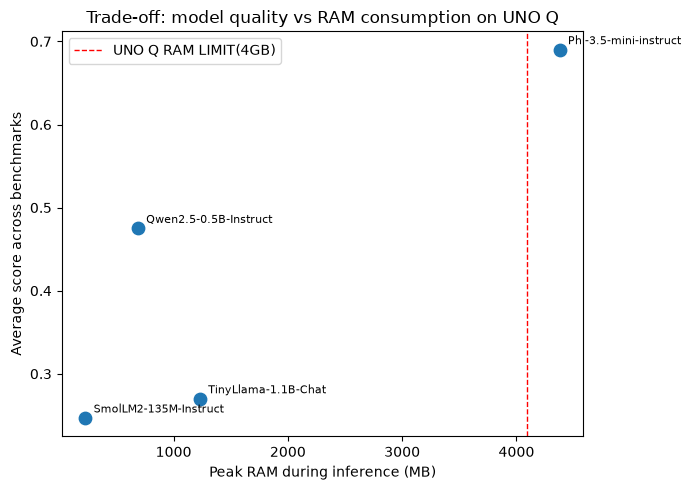

In [18]:
import matplotlib.pyplot as plt

# Chỉ vẽ những model chạy thành công (có đủ cột RAM) — một model lỗi không
# còn làm sập cả cell, và ta vẫn thấy được kết quả của các model còn lại.
ok_df = results_df[results_df.get("error").isna()].copy() if "error" in results_df.columns else results_df.copy()

if "ram_peak_mb" not in ok_df.columns or ok_df.empty:
    print("Không có model nào chạy thành công để vẽ biểu đồ — xem cột 'error' ở bảng results_df phía trên.")
else:
    task_cols = [c for c in ok_df.columns if c not in
                 ("model", "params_b", "disk_mb", "ram_idle_load_mb", "ram_avg_mb", "ram_peak_mb", "error")]
    ok_df["avg_score"] = ok_df[task_cols].mean(axis=1)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(ok_df["ram_peak_mb"], ok_df["avg_score"], s=80)
    for _, r in ok_df.iterrows():
        ax.annotate(r["model"], (r["ram_peak_mb"], r["avg_score"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax.axvline(4096, color="red", linestyle="--", linewidth=1, label="UNO Q RAM LIMIT(4GB)")
    ax.set_xlabel("Peak RAM during inference (MB)")
    ax.set_ylabel("Average score across benchmarks")
    ax.set_title("Trade-off: model quality vs RAM consumption on UNO Q")
    ax.legend()
    fig.tight_layout()
    fig.savefig("ram_vs_accuracy.png", dpi=150)
    plt.show()


## Lưu ý khi viết vào research

- Ghi rõ: quant level (Q4_K_M), context length (2048), số luồng CPU dùng,
  và **RAM tổng của thiết bị lúc benchmark** (trừ hao cho OS) — reviewer
  sẽ hỏi những con số này.
- `ram_peak_mb` là con số nên dùng để so với giới hạn cứng 4GB; `ram_avg_mb`
  phản ánh mức tiêu thụ "steady-state" khi assistant chạy lâu dài.
- Nếu một model OOM hoặc bị kill bởi OS — đó vẫn là kết quả hợp lệ, ghi vào
  bảng là "OOM / không khả thi trên thiết bị" thay vì bỏ qua.
